# 03 · Road-Network Analysis (Member 3)

**Goal.** Validate and characterise the road network (`.nodes` / `.arcs`) of every available PathSnap trip, build a
direction-preserving graph per trip, and measure connectivity so that route validation (Member 4) and the HMM / Viterbi
map-matcher can rely on it.

**Scope.** Road network only. GPS cleaning, model training, route validation and the frontend are owned by other members.
The `.track` and `.route` files are **not** read here.

| File | Columns (no header) | ID rule |
|---|---|---|
| `.nodes` | `lon lat` | `node_id` = 0-based row index |
| `.arcs` | `from_node_id to_node_id` | `arc_id` = 0-based row index (never re-indexed) |

Each trip has its **own** road network, so an `arc_id` only has meaning inside its trip.

**Reusable code.** All logic lives in [`src/pathsnap/road_network.py`](../src/pathsnap/road_network.py); this notebook only
calls it and presents the results. Raw files are read with Member 1's loader readers (`pathsnap.data.loader`).

**Contents**
1. Setup & trip discovery
2. Detailed inspection of two example trips (one train, one student-test)
3. Batch analysis of all trips (one graph in memory at a time)
4. Consolidated data-quality table & arc validation
5. Connectivity: isolated / dangling nodes, weak vs strong components
6. Degree analysis
7. Road-network visualisations
8. Graph-builder verification on real trips
9. Exported outputs & findings

## 1. Setup

In [1]:
import sys, time, warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.collections import LineCollection
from IPython.display import display

# Locate the repository root (folder containing pyproject.toml) so the notebook runs from any working directory
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

from pathsnap.data.loader import discover_trips          # Member 1's common loader (not modified)
from pathsnap.utils.config import get_raw_data_dir
from pathsnap import road_network as rn                   # Member 3's reusable module

SEED = 42                                                 # all sampling below is reproducible
rng = np.random.default_rng(SEED)
EDA_DIR = REPO_ROOT / "outputs" / "eda"
FIG_DIR = EDA_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
print("Repo root :", REPO_ROOT)
print("Raw data  :", get_raw_data_dir())
print("networkx", nx.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

Repo root : C:\Users\Mateen\OneDrive\Desktop\ML-Hackathon-PT-082
Raw data  : C:\Users\Mateen\OneDrive\Desktop\ML-Hackathon-PT-082\data\raw
networkx 3.4.2 | pandas 2.2.3 | numpy 2.1.3


### 1.1 Discover trips and partitions
Trip files are discovered with `discover_trips()` (Member 1). Partition membership comes from `configs/split.json`.
Only the two partitions we have locally are analysed: `train` (80) and `student-test` (10).

In [2]:
trips_index = discover_trips(get_raw_data_dir())
split = rn.load_split()
PARTITIONS = ["train", "student-test"]

plan = pd.DataFrame(
    [(tid, part, tid in trips_index) for part in PARTITIONS for tid in split[part]],
    columns=["trip_id", "partition", "found_on_disk"],
)
display(plan.groupby("partition")["found_on_disk"].agg(trips="size", found="sum"))
missing = plan.loc[~plan.found_on_disk, "trip_id"].tolist()
print("Trips listed in split.json but missing on disk:", missing or "none")

[INFO] 2026-11-18 11:24:10,292 - pathsnap.data.loader: Discovered 90 trips in C:\Users\Mateen\OneDrive\Desktop\ML-Hackathon-PT-082\data\raw


,trips,found
partition,,
student-test,10,10
train,80,80


Trips listed in split.json but missing on disk: none


## 2. Detailed inspection of two example trips
Before the batch run we look at one **train** trip and one **student-test** trip in full detail: first five rows, dtypes,
missing values, invalid coordinates, invalid node references and malformed rows. The same checks are then applied
programmatically to every trip in Section 3.

In [3]:
EXAMPLES = {"train": split["train"][0], "student-test": split["student-test"][0]}
example_tables = {}
for part, tid in EXAMPLES.items():
    nodes_df, arcs_df, frep = rn.load_road_network(tid, trips_index)
    example_tables[tid] = (nodes_df, arcs_df)
    print(f"=== Trip {tid} ({part}) ===")
    print(f"nodes: {len(nodes_df):,} rows | arcs: {len(arcs_df):,} rows | reader: {frep['reader']} | errors: {frep['errors'] or 'none'}")
    print("First five .nodes rows:"); display(nodes_df.head())
    print("First five .arcs rows:");  display(arcs_df.head())
    print("dtypes:", dict(nodes_df.dtypes.astype(str)), dict(arcs_df.dtypes.astype(str)))
    print("Missing values -> nodes:", int(nodes_df[["lon", "lat"]].isna().sum().sum()),
          "| arcs:", int(arcs_df[["from_node_id", "to_node_id"]].isna().sum().sum()))
    nv = rn.validate_nodes(nodes_df)
    print("Invalid coordinates:", nv["invalid_coordinates"], "| duplicate-coordinate nodes:", nv["duplicate_nodes"])
    av = rn.validate_arcs(arcs_df, len(nodes_df), nodes_df)
    print("Arcs with invalid from/to node:", int((~av.from_valid).sum()), "/", int((~av.to_valid).sum()),
          "| valid node-id range: 0 ..", len(nodes_df) - 1,
          "| observed arc node-id range:", int(arcs_df[["from_node_id", "to_node_id"]].min().min()), "..",
          int(arcs_df[["from_node_id", "to_node_id"]].max().max()))
    print("Raw-file scan (.nodes):", {k: v for k, v in frep["nodes_scan"].items() if k != "malformed_examples"})
    print("Raw-file scan (.arcs) :", {k: v for k, v in frep["arcs_scan"].items() if k != "malformed_examples"})
    print()

=== Trip 00000001 (train) ===
nodes: 88,809 rows | arcs: 165,790 rows | reader: {'nodes': 'pathsnap.data.loader', 'arcs': 'pathsnap.data.loader'} | errors: none
First five .nodes rows:


,node_id,lon,lat
0,0,8.581679,49.857880
1,1,8.584637,49.858295
2,2,8.580173,49.858567
3,3,8.584392,49.859119
4,4,8.584935,49.857396


First five .arcs rows:


,arc_id,from_node_id,to_node_id
0,0,0,281
1,1,0,1
2,2,0,5
3,3,1,0
4,4,1,40750


dtypes: {'node_id': 'int64', 'lon': 'float64', 'lat': 'float64'} {'arc_id': 'int64', 'from_node_id': 'int64', 'to_node_id': 'int64'}
Missing values -> nodes: 0 | arcs: 0
Invalid coordinates: 0 | duplicate-coordinate nodes: 8


Arcs with invalid from/to node: 0 / 0 | valid node-id range: 0 .. 88808 | observed arc node-id range: 0 .. 88808
Raw-file scan (.nodes): {'exists': True, 'total_lines': 88809, 'blank_lines': 0, 'wrong_field_count': 0, 'non_numeric_rows': 0, 'malformed_rows': 0}
Raw-file scan (.arcs) : {'exists': True, 'total_lines': 165790, 'blank_lines': 0, 'wrong_field_count': 0, 'non_numeric_rows': 0, 'malformed_rows': 0}

=== Trip 00000000 (student-test) ===
nodes: 8,542 rows | arcs: 18,196 rows | reader: {'nodes': 'pathsnap.data.loader', 'arcs': 'pathsnap.data.loader'} | errors: none
First five .nodes rows:


,node_id,lon,lat
0,0,54.335879,56.117280
1,1,54.256444,56.081855
2,2,54.257354,56.081634
3,3,54.258239,56.081233
4,4,54.258685,56.083573


First five .arcs rows:


,arc_id,from_node_id,to_node_id
0,0,0,2433
1,1,0,2475
2,2,0,2480
3,3,1,2
4,4,1,8408


dtypes: {'node_id': 'int64', 'lon': 'float64', 'lat': 'float64'} {'arc_id': 'int64', 'from_node_id': 'int64', 'to_node_id': 'int64'}
Missing values -> nodes: 0 | arcs: 0
Invalid coordinates: 0 | duplicate-coordinate nodes: 1
Arcs with invalid from/to node: 0 / 0 | valid node-id range: 0 .. 8541 | observed arc node-id range: 0 .. 8541
Raw-file scan (.nodes): {'exists': True, 'total_lines': 8542, 'blank_lines': 0, 'wrong_field_count': 0, 'non_numeric_rows': 0, 'malformed_rows': 0}
Raw-file scan (.arcs) : {'exists': True, 'total_lines': 18196, 'blank_lines': 0, 'wrong_field_count': 0, 'non_numeric_rows': 0, 'malformed_rows': 0}



## 3. Batch analysis of all trips
`rn.analyse_trip()` loads one trip, scans the raw files for malformed rows, validates nodes and arcs, builds the
`MultiDiGraph`, computes degrees / dangling nodes / components, and returns **only aggregated results**. The graph is
discarded before the next trip is processed, so at most one graph is in memory at a time.

In [4]:
summary_rows, conn_rows, flagged, dangling, heads_n, heads_a = [], [], [], [], [], []
deg_counts = {k: Counter() for k in ("in_degree", "out_degree", "total_degree")}
comp_sizes = []   # (trip_id, partition, kind, size, is_largest)

t0 = time.time()
for tid, part in plan.loc[plan.found_on_disk, ["trip_id", "partition"]].itertuples(index=False):
    res = rn.analyse_trip(tid, part, trips_index)
    summary_rows.append(res["summary"]); conn_rows.append(res["connectivity"])
    if not res["ok"]:
        print("Could not analyse", tid, res["summary"].get("load_errors")); continue
    flagged.append(res["flagged_arcs"]); dangling.append(res["dangling_nodes"])
    heads_n.append(res["nodes_head"]); heads_a.append(res["arcs_head"])
    for k in deg_counts: deg_counts[k].update(res["degree_counts"][k])
    for kind in ("wcc", "scc"):
        s = res[f"{kind}_sizes"]
        comp_sizes += [(tid, part, kind, int(x), i == 0) for i, x in enumerate(s)]
print(f"Analysed {len(summary_rows)} trips in {time.time() - t0:.1f} s")

summary = pd.DataFrame(summary_rows)
connectivity = pd.DataFrame(conn_rows)
flagged_arcs = pd.concat(flagged, ignore_index=True) if flagged else pd.DataFrame()
dangling_nodes = pd.concat(dangling, ignore_index=True) if dangling else pd.DataFrame()
components = pd.DataFrame(comp_sizes, columns=["trip_id", "partition", "component_type", "size", "is_largest"])

Analysed 90 trips in 95.2 s


### 3.1 First five rows of every trip
As required, the first five rows of `.nodes` and `.arcs` for **every** trip (saved to `outputs/eda/road_network_file_heads.csv`).

In [5]:
file_heads = (
    pd.concat([pd.concat(heads_n).assign(file="nodes"), pd.concat(heads_a).assign(file="arcs")], ignore_index=True)
    [["trip_id", "file", "node_id", "lon", "lat", "arc_id", "from_node_id", "to_node_id"]]
)
file_heads.to_csv(EDA_DIR / "road_network_file_heads.csv", index=False)
nodes_heads = pd.concat(heads_n).set_index(["trip_id", "node_id"]).sort_index()
arcs_heads = pd.concat(heads_a).set_index(["trip_id", "arc_id"]).sort_index()
with pd.option_context("display.max_rows", 1000):
    print(".nodes – first five rows per trip"); display(nodes_heads)
    print(".arcs – first five rows per trip");  display(arcs_heads)

.nodes – first five rows per trip


lon        lat
trip_id  node_id                       
00000000 0         54.335879  56.117280
         1         54.256444  56.081855
         2         54.257354  56.081634
         3         54.258239  56.081233
         4         54.258685  56.083573
00000001 0          8.581679  49.857880
         1          8.584637  49.858295
         2          8.580173  49.858567
         3          8.584392  49.859119
         4          8.584935  49.857396
00000002 0         11.025258  47.663779
         1         11.000559  47.687689
         2         11.008857  47.685018
         3         11.011122  47.683323
         4         11.020777  47.675972
00000003 0         37.206847  56.014557
         1         37.200931  56.008061
         2         37.199815  56.007847
         3         37.200271  56.007102
         4         37.179635  55.984046
00000004 0         12.369155  52.604747
         1         12.404967  52.606778
         2         12.463492  52.627797
         3         12.467539  52.635458
         4         12.370449  52.605148
00000005 0         35.554415  49.618875
         1         35.551175  49.617149
         2         35.548354  49.615422
         3         35.544226  49.612781
         4         35.539000  49.609091
00000006 0         37.317242  55.477384
         1         37.303193  55.467987
         2         37.300825  55.465828
         3         37.292007  55.452453
         4         37.290724  55.449782
00000007 0         77.115998  43.385569
         1         77.119318  43.387402
         2         77.124392  43.389735
         3         77.128201  43.391275
         4         77.131719  43.392665
00000008 0        -86.562235  34.730660
         1        -86.562747  34.730705
         2        -86.563018  34.730795
         3        -86.563174  34.730906
         4        -86.563685  34.731346
00000009 0         13.710792  42.658019
         1         13.709323  42.657094
         2         13.709356  42.657019
         3         13.709316  42.656942
         4         13.709272  42.656916
00000010 0         37.374038  55.790758
         1         37.372683  55.789246
         2         37.372289  55.788784
         3         37.371084  55.786676
         4         37.370667  55.785544
00000011 0         60.022182  56.065212
         1         60.013052  56.067294
         2         60.003781  56.065898
         3         59.998726  56.063702
         4         59.993874  56.061572
00000012 0         44.044576  36.206020
         1         44.037869  36.219150
         2         44.302226  36.264474
         3         44.038488  36.180203
         4         44.041918  36.193714
00000013 0          1.456953  43.646759
         1          1.458697  43.646729
         2          1.464074  43.646238
         3          1.466273  43.645729
         4          1.468065  43.645143
00000014 0         39.176964  51.726767
         1         39.177218  51.726872
         2         39.177818  51.727416
         3         39.173764  51.735476
         4         39.174431  51.735519
00000016 0         37.374038  55.790758
         1         37.372683  55.789246
         2         37.372289  55.788784
         3         37.371084  55.786676
         4         37.370667  55.785544
00000018 0         -8.448028  40.574529
         1         -8.449950  40.577635
         2         -8.450799  40.578956
         3         -8.450927  40.579354
         4         -8.450902  40.580506
00000019 0          7.113054  52.187221
         1          7.023960  52.194572
         2          7.085981  52.103562
         3          7.086012  52.109423
         4          7.086321  52.115195
00000020 0         24.497868  52.771606
         1         24.601557  52.772806
         2         24.589235  52.761591
         3         24.590444  52.760494
         4         24.590597  52.757606
00000021 0        106.372976  15.385097
         1        106.378186  15.387791
         2        106.384022  15.389559
         3        106.385

.arcs – first five rows per trip


from_node_id  to_node_id
trip_id  arc_id                          
00000000 0                  0        2433
         1                  0        2475
         2                  0        2480
         3                  1           2
         4                  1        8408
00000001 0                  0         281
         1                  0           1
         2                  0           5
         3                  1           0
         4                  1       40750
00000002 0                  0        1492
         1                  0         463
         2                  0         462
         3                  1         878
         4                  1         879
00000003 0                  0        7838
         1                  0        3594
         2                  0         154
         3                  1        2713
         4                  1        5029
00000004 0                  0         371
         1                  0         370
         2                  1        2233
         3                  1        2231
         4                  1        1129
00000005 0                  1           0
         1                  2           1
         2                  3           2
         3                  4           3
         4                  5           4
00000006 0                  0         151
         1                  0         646
         2                  1        1337
         3                  1        1271
         4                  2         433
00000007 0                  0         651
         1                  0         750
         2                  1         327
         3                  1         456
         4                  2         397
00000008 0                  0           1
         1                  0        3466
         2                  0        3467
         3                  1           0
         4                  1           2
00000009 0                  0          33
         1                  0         686
         2                  1          13
         3                  1        1687
         4                  2          32
00000010 0                  0         224
         1                  1          35
         2                  2           1
         3                  3        2246
         4                  3        6452
00000011 0                  0          60
         1                  0          57
         2                  0         196
         3                  1         414
         4                  1         409
00000012 0                  0         500
         1                  1         537
         2                  2        3496
         3                  2         388
         4                  3         464
00000013 0                  0      154609
         1                  1       34914
         2                  2       16896
         3                  3       34918
         4                  4        5455
00000014 0                  0         589
         1                  0           1
         2                  0         591
         3                  1           0
         4                  1           2
00000016 0                  0         218
         1                  1          35
         2                  2           1
         3                  3        2211
         4                  3        6297
00000018 0                  0         102
         1                  0          29
         2                  1        5928
         3                  1         109
         4                  2        2388
00000019 0                  0       14795
         1                  1       31469
         2                  1       14295
         3                  1        9729
         4                  2       14880
00000020 0                  0           5
         1                  1        1187
         2                  2        1351
         3                 

## 4. Consolidated data-quality table

In [6]:
consolidated = summary[[
    "trip_id", "partition", "n_nodes", "n_arcs", "missing_coordinates", "invalid_node_references",
    "duplicate_nodes", "duplicate_arcs", "self_loops",
]].rename(columns={
    "trip_id": "Trip ID", "partition": "Partition", "n_nodes": "Number of nodes", "n_arcs": "Number of arcs",
    "missing_coordinates": "Missing coordinates", "invalid_node_references": "Invalid node references",
    "duplicate_nodes": "Duplicate nodes", "duplicate_arcs": "Duplicate arcs", "self_loops": "Self-loops",
})
with pd.option_context("display.max_rows", 100):
    display(consolidated)

,Trip ID,Partition,Number of nodes,Number of arcs,Missing coordinates,Invalid node references,Duplicate nodes,Duplicate arcs,Self-loops
0,00000001,train,88809,165790,0,0,8,292,0
1,00000002,train,7936,16139,0,0,0,0,0
2,00000003,train,9138,18028,0,0,3,6,0
3,00000004,train,7350,15499,0,0,1,5,0
4,00000005,train,898,1579,0,0,0,0,0
5,00000006,train,3259,6757,0,0,0,0,0
6,00000008,train,4995,10421,0,0,1,12,0
7,00000010,train,8502,15715,0,0,0,7,0
8,00000011,train,2649,5393,0,0,0,0,0
9,00000012,train,16376,38599,0,0,0,0,0


In [7]:
checks = {
    "Trips analysed": len(summary),
    "Total nodes": int(summary.n_nodes.sum()),
    "Total arcs": int(summary.n_arcs.sum()),
    "Malformed .nodes rows": int(summary.malformed_node_rows.sum()),
    "Malformed .arcs rows": int(summary.malformed_arc_rows.sum()),
    "Blank lines": int(summary.blank_lines.sum()),
    "Missing coordinates": int(summary.missing_coordinates.sum()),
    "Invalid coordinates (out of range / non-finite / 0,0)": int(summary.invalid_coordinates.sum()),
    "Invalid node references (arc endpoints outside 0..n-1)": int(summary.invalid_node_references.sum()),
    "Duplicate-coordinate nodes": int(summary.duplicate_nodes.sum()),
    "Trips with duplicate-coordinate nodes": int((summary.duplicate_nodes > 0).sum()),
    "Duplicate directed arcs": int(summary.duplicate_arcs.sum()),
    "Trips with duplicate arcs": int((summary.duplicate_arcs > 0).sum()),
    "Self-loops": int(summary.self_loops.sum()),
    "Trips with self-loops": int((summary.self_loops > 0).sum()),
    "Zero-length arcs": int(summary.zero_length_arcs.sum()),
    "Load errors": int((summary.load_errors.fillna("") != "").sum()),
    "Distinct node dtypes": sorted(set(summary.lon_dtype) | set(summary.lat_dtype)),
    "Distinct arc dtypes": sorted(set(summary.arc_dtype)),
}
quality_overview = pd.Series(checks, name="value").to_frame()
display(quality_overview)
display(summary.groupby("partition")[["n_nodes", "n_arcs", "total_length_km", "median_arc_length_m", "two_way_arc_share"]]
        .describe().T.round(2))

,value
Trips analysed,90
Total nodes,2024174
Total arcs,4061945
Malformed .nodes rows,0
Malformed .arcs rows,0
Blank lines,0
Missing coordinates,0
"Invalid coordinates (out of range / non-finite / 0,0)",0
Invalid node references (arc endpoints outside 0..n-1),0
Duplicate-coordinate nodes,92


partition                  student-test      train
n_nodes             count         10.00      80.00
                    mean        9068.90   24168.56
                    std         7452.18   32272.30
                    min         1770.00     299.00
                    25%         4908.00    3487.75
                    50%         6596.50    9608.00
                    75%        11844.25   28846.75
                    max        26635.00  155003.00
n_arcs              count         10.00      80.00
                    mean       18504.10   48461.30
                    std        15496.93   64738.84
                    min         3577.00     649.00
                    25%        10292.25    7061.75
                    50%        13145.00   19526.50
                    75%        24818.50   58003.25
                    max        56027.00  307392.00
total_length_km     count         10.00      80.00
                    mean         853.88    2159.47
                    std          641.93    3201.55
                    min          223.91      60.23
                    25%          388.37     287.15
                    50%          559.46     863.69
                    75%         1480.35    2323.18
                    max         1791.70   18501.43
median_arc_length_m count         10.00      80.00
                    mean          31.35      30.36
                    std           12.13      15.74
                    min           15.83       6.74
                    25%           20.23      21.44
                    50%           31.86      24.55
                    75%           40.12      35.05
                    max           53.24      84.90
two_way_arc_share   count         10.00      80.00
                    mean           0.93       0.92
                    std            0.06       0.09
                    min            0.86       0.35
                    25%            0.87       0.90
                    50%            0.93       0.95
                    75%            0.98       0.98
                    max            1.00       1.00

### 4.1 Arc validation details
Every arc is checked by `rn.validate_arcs()` and keeps its **original `arc_id`**. Definitions:

* **invalid reference** – `from_node_id` or `to_node_id` is outside `0 … n_nodes-1` (such arcs cannot be put in the graph but stay in the report);
* **self-loop** – `from_node_id == to_node_id`;
* **duplicate directed connection** – an ordered pair `(from, to)` that already appeared at a lower `arc_id`;
* **parallel edges** – all arcs sharing the same ordered pair (the first occurrence plus its duplicates);
* **two-way share** – fraction of arcs whose reverse arc `(to, from)` also exists (i.e. bidirectional streets).

Nothing is deleted: duplicates and self-loops remain in the graph as separate edges keyed by `arc_id`, because a ground-truth
route may reference any of them. The table below lists every arc with at least one flag.

In [8]:
print("Flagged arcs:", len(flagged_arcs))
if len(flagged_arcs):
    issue_counts = flagged_arcs["issues"].str.split(";").explode().value_counts().rename("arcs")
    display(issue_counts.to_frame())
    display(flagged_arcs.head(15))
    print("Max parallel_count observed:", int(flagged_arcs.parallel_count.max()))
    print("Arcs with an invalid node reference:", int((~flagged_arcs.is_valid).sum()))
flagged_arcs.to_csv(EDA_DIR / "invalid_arcs_report.csv", index=False)

Flagged arcs: 1915


,arcs
issues,
duplicate_connection,1903
self_loop,24


,trip_id,arc_id,from_node_id,to_node_id,from_valid,to_valid,is_self_loop,parallel_count,is_parallel,is_duplicate,has_reverse,endpoint_bad_coords,is_valid,issues,in_graph
0,00000001,8631,5073,28089,True,True,False,2,True,True,True,False,True,duplicate_connection,True
1,00000001,8632,5073,5074,True,True,False,2,True,True,True,False,True,duplicate_connection,True
2,00000001,8639,5076,28925,True,True,False,2,True,True,True,False,True,duplicate_connection,True
3,00000001,8642,5077,33427,True,True,False,2,True,True,True,False,True,duplicate_connection,True
4,00000001,9496,5467,39277,True,True,False,2,True,True,True,False,True,duplicate_connection,True
5,00000001,10357,5908,22809,True,True,False,2,True,True,True,False,True,duplicate_connection,True
6,00000001,10861,6231,83575,True,True,False,2,True,True,True,False,True,duplicate_connection,True
7,00000001,10862,6231,40908,True,True,False,2,True,True,True,False,True,duplicate_connection,True
8,00000001,10867,6232,83570,True,True,False,2,True,True,True,False,True,duplicate_connection,True
9,00000001,10868,6232,83562,True,True,False,2,True,True,True,False,True,duplicate_connection,True


Max parallel_count observed: 3
Arcs with an invalid node reference: 0


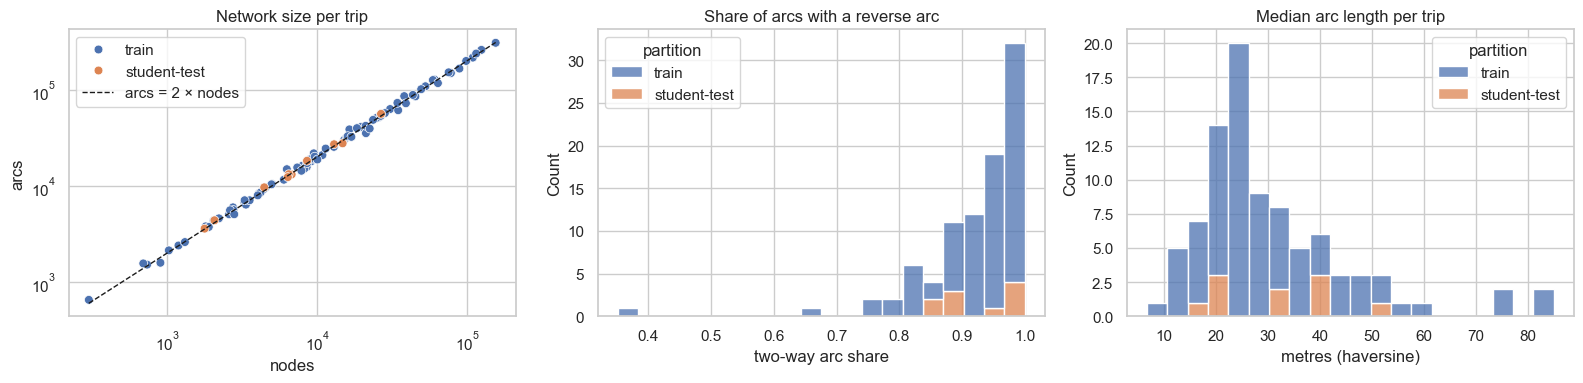

arcs/nodes ratio: median 2.033, min 1.667, max 2.373


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.scatterplot(data=summary, x="n_nodes", y="n_arcs", hue="partition", ax=axes[0], s=40)
axes[0].set(xscale="log", yscale="log", title="Network size per trip", xlabel="nodes", ylabel="arcs")
lim = [summary.n_nodes.min(), summary.n_nodes.max()]
axes[0].plot(lim, [2 * x for x in lim], "k--", lw=1, label="arcs = 2 × nodes"); axes[0].legend()
sns.histplot(data=summary, x="two_way_arc_share", hue="partition", bins=20, ax=axes[1], multiple="stack")
axes[1].set(title="Share of arcs with a reverse arc", xlabel="two-way arc share")
sns.histplot(data=summary, x="median_arc_length_m", hue="partition", bins=20, ax=axes[2], multiple="stack")
axes[2].set(title="Median arc length per trip", xlabel="metres (haversine)")
plt.tight_layout(); plt.savefig(FIG_DIR / "network_size_overview.png", dpi=120); plt.show()
print("arcs/nodes ratio: median %.3f, min %.3f, max %.3f" % tuple((summary.n_arcs / summary.n_nodes).agg(["median", "min", "max"])))

## 5. Connectivity analysis

### Weak vs strong connectivity
* A **weakly connected component (WCC)** is a set of nodes that are connected if arc directions are *ignored*. It
  answers "is this piece of road physically attached to the rest of the map?".
* A **strongly connected component (SCC)** is a set of nodes in which every node can reach every other node *following*
  arc directions. It answers "can a vehicle drive from anywhere to anywhere here, obeying one-way rules?".

Every SCC lies inside one WCC, so `#SCC ≥ #WCC` and `largest SCC ≤ largest WCC`. For map matching, the gap matters:
if consecutive GPS candidates lie in different SCCs, a legal directed path between them may not exist, and the HMM
transition probability will be zero unless we handle it (e.g. allow the reverse direction or penalise rather than forbid).

### 5.1 Isolated and dangling nodes
`rn.find_isolated_nodes()` puts each problematic node into one category:

| category | in-degree | out-degree | meaning |
|---|---|---|---|
| `isolated` | 0 | 0 | no arc touches the node |
| `source_only` | 0 | > 0 | can be left but never entered (dangling start) |
| `sink_only` | > 0 | 0 | can be entered but never left (dead end) |

In [10]:
conn_cols = ["trip_id", "partition", "n_nodes", "n_edges", "n_weak_components", "n_strong_components",
             "largest_wcc_size", "largest_scc_size", "largest_wcc_pct", "largest_scc_pct",
             "singleton_wccs", "singleton_sccs", "isolated_nodes", "source_only_nodes", "sink_only_nodes"]
with pd.option_context("display.max_rows", 100):
    display(connectivity[conn_cols])

,trip_id,partition,n_nodes,n_edges,n_weak_components,n_strong_components,largest_wcc_size,largest_scc_size,largest_wcc_pct,largest_scc_pct,singleton_wccs,singleton_sccs,isolated_nodes,source_only_nodes,sink_only_nodes
0,00000001,train,88809,165790,175,1942,86854,84999,97.799,95.710,0,1750,0,69,81
1,00000002,train,7936,16139,14,14,7750,7750,97.656,97.656,0,0,0,0,0
2,00000003,train,9138,18028,42,167,8625,8235,94.386,90.118,0,115,0,7,6
3,00000004,train,7350,15499,12,14,7254,7252,98.694,98.667,0,2,0,1,0
4,00000005,train,898,1579,3,153,888,571,98.886,63.586,0,148,0,2,2
5,00000006,train,3259,6757,8,8,2943,2943,90.304,90.304,0,0,0,0,0
6,00000008,train,4995,10421,13,209,4913,4688,98.358,93.854,0,194,0,10,7
7,00000010,train,8502,15715,28,411,7941,7272,93.402,85.533,0,372,0,12,8
8,00000011,train,2649,5393,2,2,2641,2641,99.698,99.698,0,0,0,0,0
9,00000012,train,16376,38599,22,165,16088,14914,98.241,91.072,0,133,0,14,17


In [11]:
print("Zero in-degree nodes  (isolated + source_only):", int(connectivity.isolated_nodes.sum() + connectivity.source_only_nodes.sum()))
print("Zero out-degree nodes (isolated + sink_only)  :", int(connectivity.isolated_nodes.sum() + connectivity.sink_only_nodes.sum()))
print("Zero total-degree (isolated) nodes            :", int(connectivity.isolated_nodes.sum()))
display(dangling_nodes["category"].value_counts().rename("nodes").to_frame())
print("Trips with at least one dangling node:", dangling_nodes.trip_id.nunique(), "of", len(connectivity))
dangling_nodes.to_csv(EDA_DIR / "isolated_nodes_report.csv", index=False)
display(dangling_nodes.head(10))

Zero in-degree nodes  (isolated + source_only): 952
Zero out-degree nodes (isolated + sink_only)  : 955
Zero total-degree (isolated) nodes            : 0


,nodes
category,
sink_only,955
source_only,952


Trips with at least one dangling node: 68 of 90


,trip_id,node_id,longitude,latitude,in_degree,out_degree,total_degree,category
0,00000001,1601,8.561361,49.882972,1,0,1,sink_only
1,00000001,1603,8.561183,49.882745,0,1,1,source_only
2,00000001,1919,8.567886,50.051947,0,1,1,source_only
3,00000001,2519,8.560835,50.081518,0,1,1,source_only
4,00000001,2534,8.560778,50.081625,1,0,1,sink_only
5,00000001,2563,8.561495,50.052217,0,1,1,source_only
6,00000001,3206,8.657494,49.870877,1,0,1,sink_only
7,00000001,3400,8.560643,50.137134,1,0,1,sink_only
8,00000001,4514,8.657241,50.131667,1,0,1,sink_only
9,00000001,5755,8.657791,50.078584,1,0,1,sink_only


A singleton weak component normally means an isolated node. Where a trip has a singleton WCC but **no** isolated node,
the node must carry arcs that only connect it to itself (self-loops). The next cell checks this directly.

In [12]:
odd = connectivity[(connectivity.singleton_wccs > 0) & (connectivity.isolated_nodes == 0)]
for tid in odd.trip_id:
    n_df, a_df, _ = rn.load_road_network(tid, trips_index, scan=False)
    G_tmp, _, _ = rn.build_road_graph(n_df, a_df)
    singles = [next(iter(c)) for c in nx.weakly_connected_components(G_tmp) if len(c) == 1]
    for n in singles:
        arcs_here = [(u, v, k) for u, v, k in G_tmp.edges(n, keys=True)]
        print(f"trip {tid}: singleton WCC node {n} -> arcs (from, to, arc_id) = {arcs_here}")
    del G_tmp

trip 00000035: singleton WCC node 18927 -> arcs (from, to, arc_id) = [(18927, 18927, 31470), (18927, 18927, 31471)]


### 5.2 Component statistics

In [13]:
display(connectivity.groupby("partition")[["n_weak_components", "n_strong_components", "largest_wcc_pct", "largest_scc_pct"]]
        .describe().T.round(2))
print("Trips that are weakly connected  :", int(connectivity.is_weakly_connected.sum()))
print("Trips that are strongly connected:", int(connectivity.is_strongly_connected.sum()))
worst = connectivity.nsmallest(5, "largest_wcc_pct")[["trip_id", "partition", "n_nodes", "n_weak_components", "largest_wcc_pct", "second_wcc_size", "largest_scc_pct"]]
print("Trips with the most fragmented networks:"); display(worst)

partition                  student-test    train
n_weak_components   count         10.00    80.00
                    mean          22.70    39.01
                    std           29.18    60.68
                    min            5.00     1.00
                    25%            7.25     9.75
                    50%           11.00    20.00
                    75%           21.75    42.25
                    max          100.00   421.00
n_strong_components count         10.00    80.00
                    mean          97.40   250.48
                    std          125.96   343.24
                    min            6.00     2.00
                    25%           21.75    15.50
                    50%           53.50   127.00
                    75%           94.75   328.50
                    max          415.00  1942.00
largest_wcc_pct     count         10.00    80.00
                    mean          96.39    96.90
                    std            3.40     3.88
                    min           87.40    69.28
                    25%           96.40    96.35
                    50%           97.06    98.11
                    75%           98.31    98.72
                    max           99.07   100.00
largest_scc_pct     count         10.00    80.00
                    mean          94.16    94.97
                    std            5.40     5.69
                    min           81.69    63.59
                    25%           94.68    93.81
                    50%           96.10    96.42
                    75%           97.25    98.15
                    max           98.44    99.96

Trips that are weakly connected  : 1
Trips that are strongly connected: 0
Trips with the most fragmented networks:


,trip_id,partition,n_nodes,n_weak_components,largest_wcc_pct,second_wcc_size,largest_scc_pct
75,00000095,train,1888,7,69.280,462,69.280
80,00000000,student-test,8542,100,87.403,102,87.357
58,00000072,train,3275,6,88.977,315,88.977
5,00000006,train,3259,8,90.304,270,90.304
64,00000081,train,2791,8,90.505,66,90.505


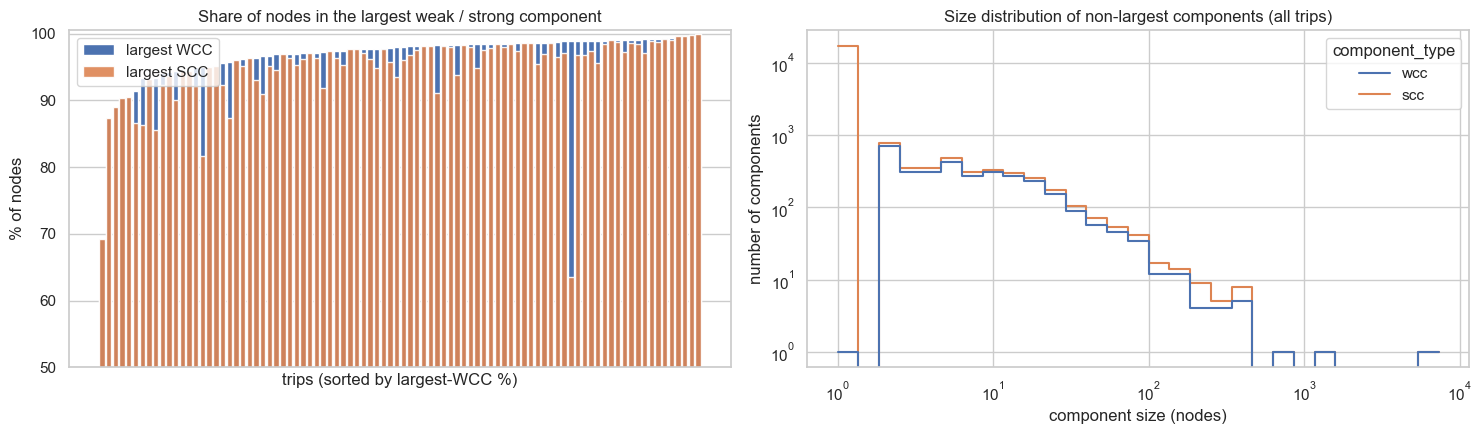

Non-largest WCC sizes: {'count': 3258.0, 'mean': 15.3, 'std': 109.8, 'min': 1.0, '25%': 3.0, '50%': 6.0, '75%': 13.0, 'max': 5844.0}
Non-largest SCC sizes: {'count': 20922.0, 'mean': 3.6, 'std': 43.5, 'min': 1.0, '25%': 1.0, '50%': 1.0, '75%': 1.0, 'max': 5792.0}


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
order = connectivity.sort_values("largest_wcc_pct")
x = np.arange(len(order))
axes[0].bar(x, order.largest_wcc_pct, label="largest WCC", color="#4C72B0")
axes[0].bar(x, order.largest_scc_pct, label="largest SCC", color="#DD8452", alpha=0.9)
axes[0].set(ylim=(50, 100.5), xticks=[], xlabel="trips (sorted by largest-WCC %)", ylabel="% of nodes",
            title="Share of nodes in the largest weak / strong component")
axes[0].legend()

small = components[~components.is_largest]
bins = np.logspace(0, np.log10(max(small["size"].max(), 2)) + 0.1, 30)
sns.histplot(data=small, x="size", hue="component_type", bins=bins, ax=axes[1], element="step", fill=False)
axes[1].set(xscale="log", yscale="log", title="Size distribution of non-largest components (all trips)",
            xlabel="component size (nodes)", ylabel="number of components")
plt.tight_layout(); plt.savefig(FIG_DIR / "component_sizes.png", dpi=120); plt.show()

comp_dist = components.groupby(["component_type", "is_largest", "size"]).size().rename("count").reset_index()
comp_dist.to_csv(EDA_DIR / "component_size_distribution.csv", index=False)
print("Non-largest WCC sizes:", small.query("component_type=='wcc'")["size"].describe().round(1).to_dict())
print("Non-largest SCC sizes:", small.query("component_type=='scc'")["size"].describe().round(1).to_dict())

## 6. Node-degree analysis
Degrees are counted on the `MultiDiGraph`, so parallel arcs count separately and a self-loop adds one to both in- and
out-degree. Distributions below aggregate **all nodes of all trips**.

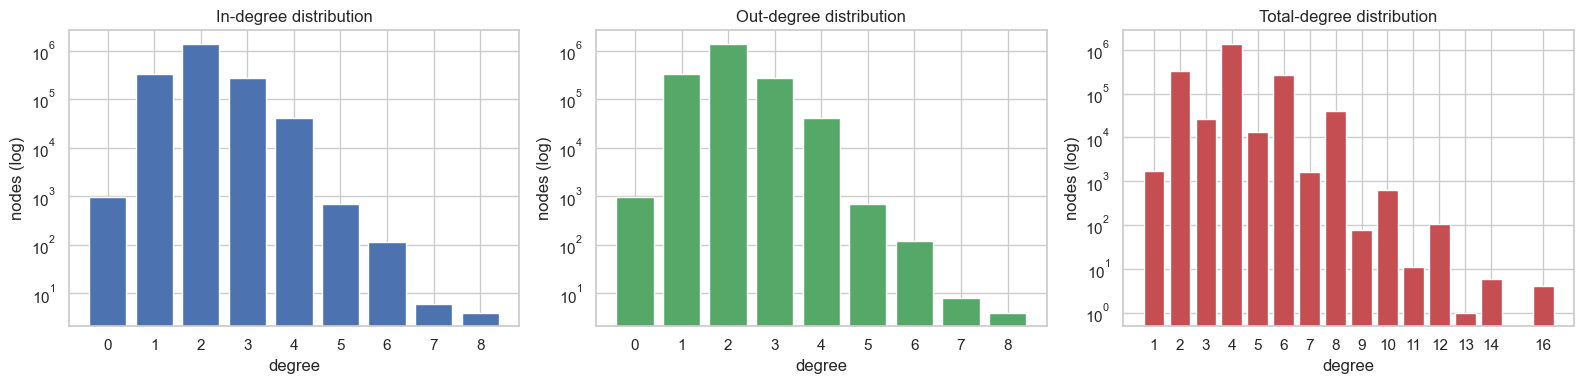

kind,in_degree,out_degree,total_degree
degree,,,
0,0.047,0.047,0.000
1,16.640,16.635,0.086
2,67.984,67.995,15.947
3,13.300,13.291,1.284
4,1.990,1.991,67.039
5,0.034,0.034,0.647
6,0.006,0.006,12.932
7,0.000,0.000,0.080
8,0.000,0.000,1.943


In [15]:
deg_dist = pd.concat(
    [pd.Series(c, name="nodes").rename_axis("degree").reset_index().assign(kind=k) for k, c in deg_counts.items()],
    ignore_index=True,
).sort_values(["kind", "degree"])
deg_dist["share_pct"] = 100 * deg_dist.nodes / deg_dist.groupby("kind").nodes.transform("sum")
deg_dist.to_csv(EDA_DIR / "degree_distribution.csv", index=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, k, c in zip(axes, ["in_degree", "out_degree", "total_degree"], ["#4C72B0", "#55A868", "#C44E52"]):
    d = deg_dist[deg_dist.kind == k]
    ax.bar(d.degree, d.nodes, color=c)
    ax.set(yscale="log", title=k.replace("_", "-").capitalize() + " distribution", xlabel="degree", ylabel="nodes (log)")
    ax.set_xticks(d.degree)
plt.tight_layout(); plt.savefig(FIG_DIR / "degree_distributions.png", dpi=120); plt.show()
display(deg_dist.pivot(index="degree", columns="kind", values="share_pct").round(3).fillna(0))

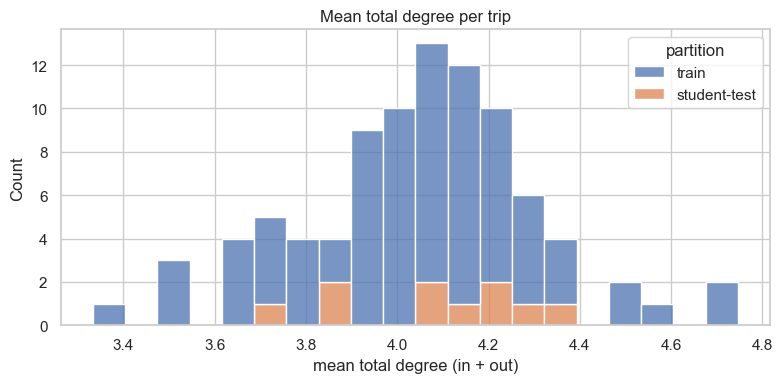

Mean total degree: median 4.065, range 3.333 – 4.746
Max total degree over all trips: 16


In [16]:
# Mean / max degree per trip
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(data=connectivity, x="mean_total_degree", hue="partition", multiple="stack", bins=20, ax=ax)
ax.set(title="Mean total degree per trip", xlabel="mean total degree (in + out)")
plt.tight_layout(); plt.savefig(FIG_DIR / "mean_degree_per_trip.png", dpi=120); plt.show()
print("Mean total degree: median %.3f, range %.3f – %.3f" % tuple(connectivity.mean_total_degree.agg(["median", "min", "max"])))
print("Max total degree over all trips:", int(connectivity.max_total_degree.max()))

## 7. Road-network visualisations
Coordinates are plotted as longitude / latitude, with the aspect ratio corrected by `1 / cos(latitude)` so that
distances look right. Edges are drawn as a single `LineCollection` (fast even for tens of thousands of segments).

**Representative trip.** The `train` trip whose arc count is closest to the training-set median is used, so the
figures show a typical network rather than the smallest or largest one.

Representative trip 00000022: 9,607 nodes, 18,982 edges, 746.5 km of directed arcs


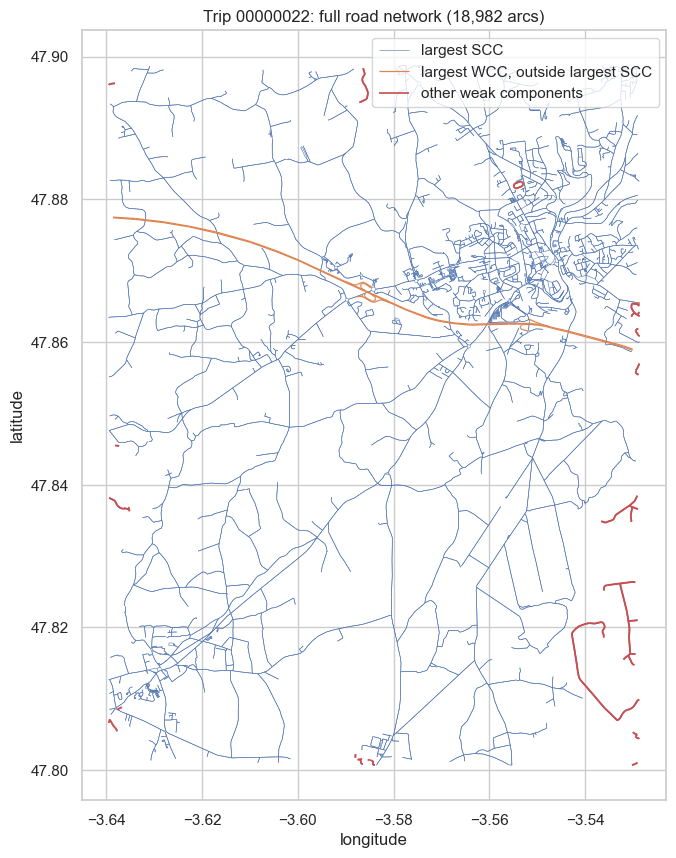

In [17]:
train_sum = summary[summary.partition == "train"]
REP = train_sum.iloc[(train_sum.n_arcs - train_sum.n_arcs.median()).abs().argsort().iloc[0]].trip_id
nodes_rep, arcs_rep, _ = rn.load_road_network(REP, trips_index, scan=False)
G_rep, val_rep, summ_rep = rn.build_road_graph(nodes_rep, arcs_rep)
geo_rep = rn.get_road_segment_geometry(nodes_rep, arcs_rep)
print(f"Representative trip {REP}: {G_rep.number_of_nodes():,} nodes, {G_rep.number_of_edges():,} edges, "
      f"{summ_rep['total_length_km']:.1f} km of directed arcs")

def plot_segments(ax, geo, **kw):
    segs = np.stack([geo[["from_lon", "from_lat"]].to_numpy(), geo[["to_lon", "to_lat"]].to_numpy()], axis=1)
    ax.add_collection(LineCollection(segs, **kw))
    ax.autoscale()
    ax.set_aspect(1 / np.cos(np.radians(np.nanmean(geo.from_lat))))
    ax.set_xlabel("longitude"); ax.set_ylabel("latitude")

# Components of the representative trip
_, sizes_rep = rn.calculate_connectivity_statistics(G_rep, return_sizes=True)
in_lwcc = np.isin(geo_rep.from_node_id, list(sizes_rep["largest_wcc"]))
in_lscc = np.isin(geo_rep.from_node_id, list(sizes_rep["largest_scc"])) & np.isin(geo_rep.to_node_id, list(sizes_rep["largest_scc"]))

fig, ax = plt.subplots(figsize=(10, 10))
plot_segments(ax, geo_rep[in_lscc], colors="#4C72B0", linewidths=0.4, label="largest SCC")
plot_segments(ax, geo_rep[in_lwcc & ~in_lscc], colors="#DD8452", linewidths=0.9, label="largest WCC, outside largest SCC")
plot_segments(ax, geo_rep[~in_lwcc], colors="#C44E52", linewidths=1.2, label="other weak components")
ax.legend(loc="upper right")
ax.set_title(f"Trip {REP}: full road network ({len(geo_rep):,} arcs)")
plt.savefig(FIG_DIR / f"network_full_{REP}.png", dpi=130, bbox_inches="tight"); plt.show()

### 7.1 Enlarged region
A square window of about 800 m × 800 m is centred on the node closest to the **median longitude / latitude** of the
network (a deterministic choice that lands in the dense core). Every arc with at least one endpoint inside the window is
drawn (clipped at the window border), and nodes inside the window are coloured by total degree.

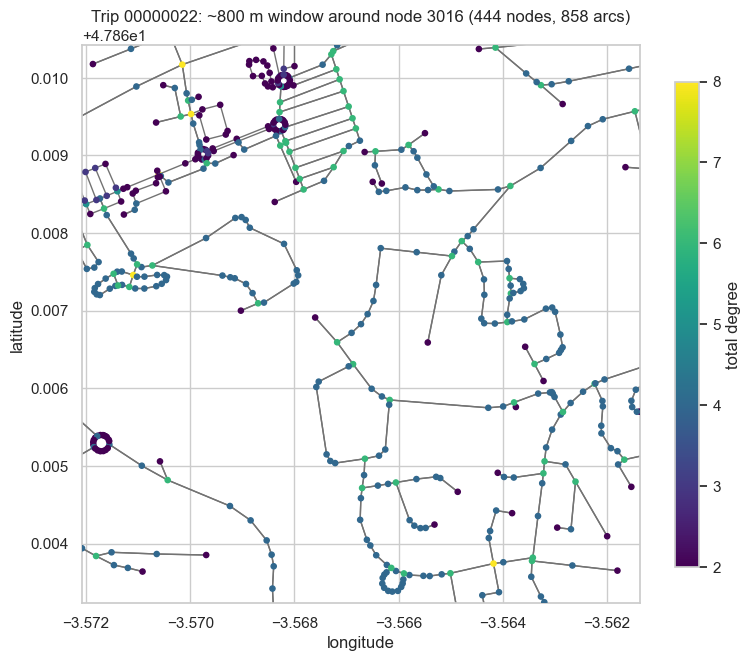

In [18]:
def window(nodes_df, centre_lon, centre_lat, half_m):
    dlat = half_m / 111_320.0
    dlon = half_m / (111_320.0 * np.cos(np.radians(centre_lat)))
    m = nodes_df.lon.between(centre_lon - dlon, centre_lon + dlon) & nodes_df.lat.between(centre_lat - dlat, centre_lat + dlat)
    return set(nodes_df.loc[m, "node_id"]), (centre_lon - dlon, centre_lon + dlon, centre_lat - dlat, centre_lat + dlat)

med_lon, med_lat = nodes_rep.lon.median(), nodes_rep.lat.median()
centre = nodes_rep.iloc[rn.haversine_m(nodes_rep.lon, nodes_rep.lat, med_lon, med_lat).argmin()]
win_nodes, bbox = window(nodes_rep, centre.lon, centre.lat, 400)
geo_win = geo_rep[geo_rep.from_node_id.isin(win_nodes) | geo_rep.to_node_id.isin(win_nodes)]
deg_rep = rn.calculate_node_degrees(G_rep).set_index("node_id")
nw = nodes_rep[nodes_rep.node_id.isin(win_nodes)]

fig, ax = plt.subplots(figsize=(9, 9))
plot_segments(ax, geo_win, colors="0.45", linewidths=1.0)
ax.set_xlim(bbox[0], bbox[1]); ax.set_ylim(bbox[2], bbox[3])
sc = ax.scatter(nw.lon, nw.lat, c=deg_rep.loc[nw.node_id, "total_degree"], cmap="viridis", s=14, zorder=3)
plt.colorbar(sc, ax=ax, shrink=0.7, label="total degree")
ax.set_title(f"Trip {REP}: ~800 m window around node {int(centre.node_id)} ({len(nw)} nodes, {len(geo_win)} arcs)")
plt.savefig(FIG_DIR / f"network_zoom_{REP}.png", dpi=130, bbox_inches="tight"); plt.show()

### 7.2 Node connections (directed)
A smaller window (~300 m × 300 m, same centre) shows individual nodes and the **direction** of each arc, using the
`MultiDiGraph` itself (`G.subgraph`). Arcs whose reverse arc also exists (two-way streets) are grey; one-way arcs are red.
Node labels are the original `node_id`s.

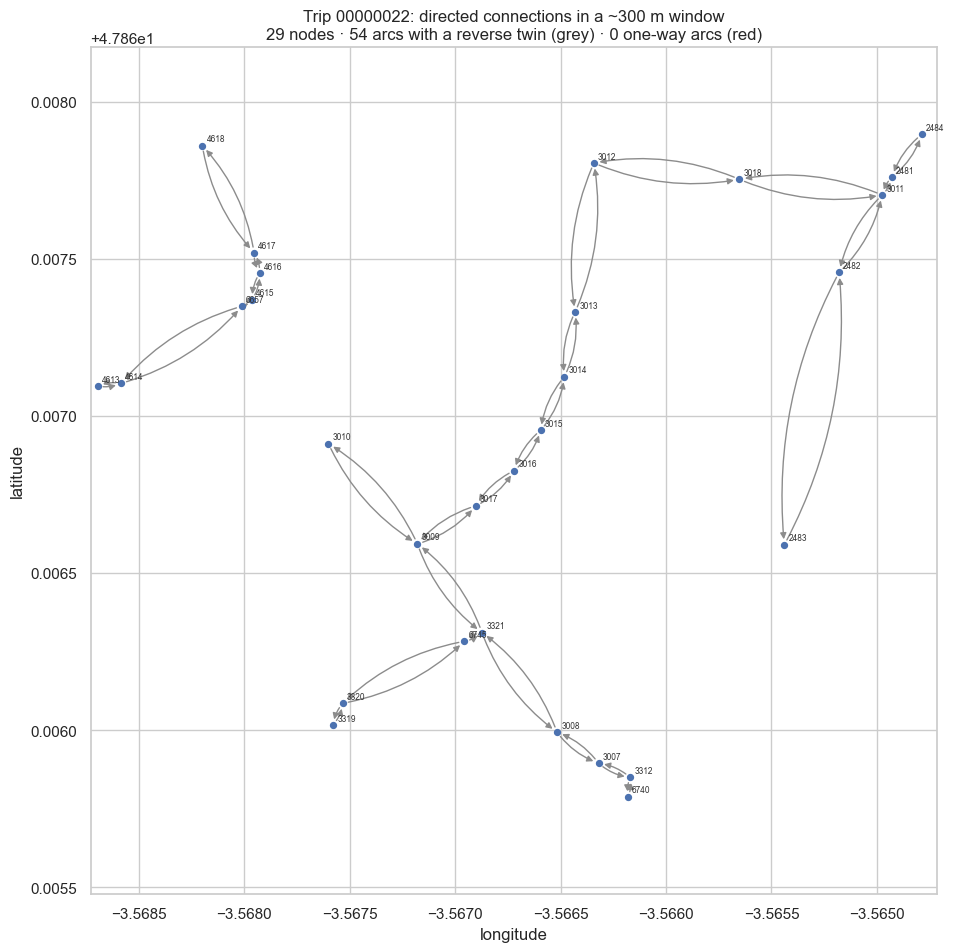

In [19]:
small_nodes, sb = window(nodes_rep, centre.lon, centre.lat, 150)
H = G_rep.subgraph(small_nodes)
fig, ax = plt.subplots(figsize=(11, 11))
n_two = n_one = 0
for u, v, k in H.edges(keys=True):
    if u == v:
        continue
    two = H.has_edge(v, u)
    n_two += two; n_one += not two
    (x0, y0), (x1, y1) = [(H.nodes[n]["longitude"], H.nodes[n]["latitude"]) for n in (u, v)]
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0),
                arrowprops=dict(arrowstyle="-|>", color="0.55" if two else "#C44E52", lw=1.0 if two else 1.8,
                                shrinkA=4, shrinkB=4, mutation_scale=9 if two else 13,
                                connectionstyle="arc3,rad=0.15" if two else "arc3,rad=0"))
xs = [H.nodes[n]["longitude"] for n in H]; ys = [H.nodes[n]["latitude"] for n in H]
ax.scatter(xs, ys, s=18, color="#4C72B0", zorder=3)
for n, x, y in zip(H.nodes, xs, ys):
    ax.annotate(str(n), (x, y), xytext=(3, 3), textcoords="offset points", fontsize=6, color="0.2")
ax.set_xlim(sb[0], sb[1]); ax.set_ylim(sb[2], sb[3])
ax.set_aspect(1 / np.cos(np.radians(centre.lat)))
ax.set(xlabel="longitude", ylabel="latitude",
       title=f"Trip {REP}: directed connections in a ~300 m window\n"
             f"{H.number_of_nodes()} nodes · {n_two} arcs with a reverse twin (grey) · {n_one} one-way arcs (red)")
plt.savefig(FIG_DIR / f"network_connections_{REP}.png", dpi=130, bbox_inches="tight"); plt.show()

### 7.3 Isolated / dangling nodes and disconnected pieces
No trip contains fully isolated nodes (Section 5.1), so the figure shows the next most relevant problems, one trip per panel:

* **left** – the trip with the **lowest share of nodes in its largest WCC** (most fragmented network); arcs outside the
  largest weak component are highlighted;
* **right** – the trip with the **most dangling nodes** (source-only ▲ / sink-only ▼).

Each trip is loaded, plotted and released before the next one, keeping a single graph in memory.

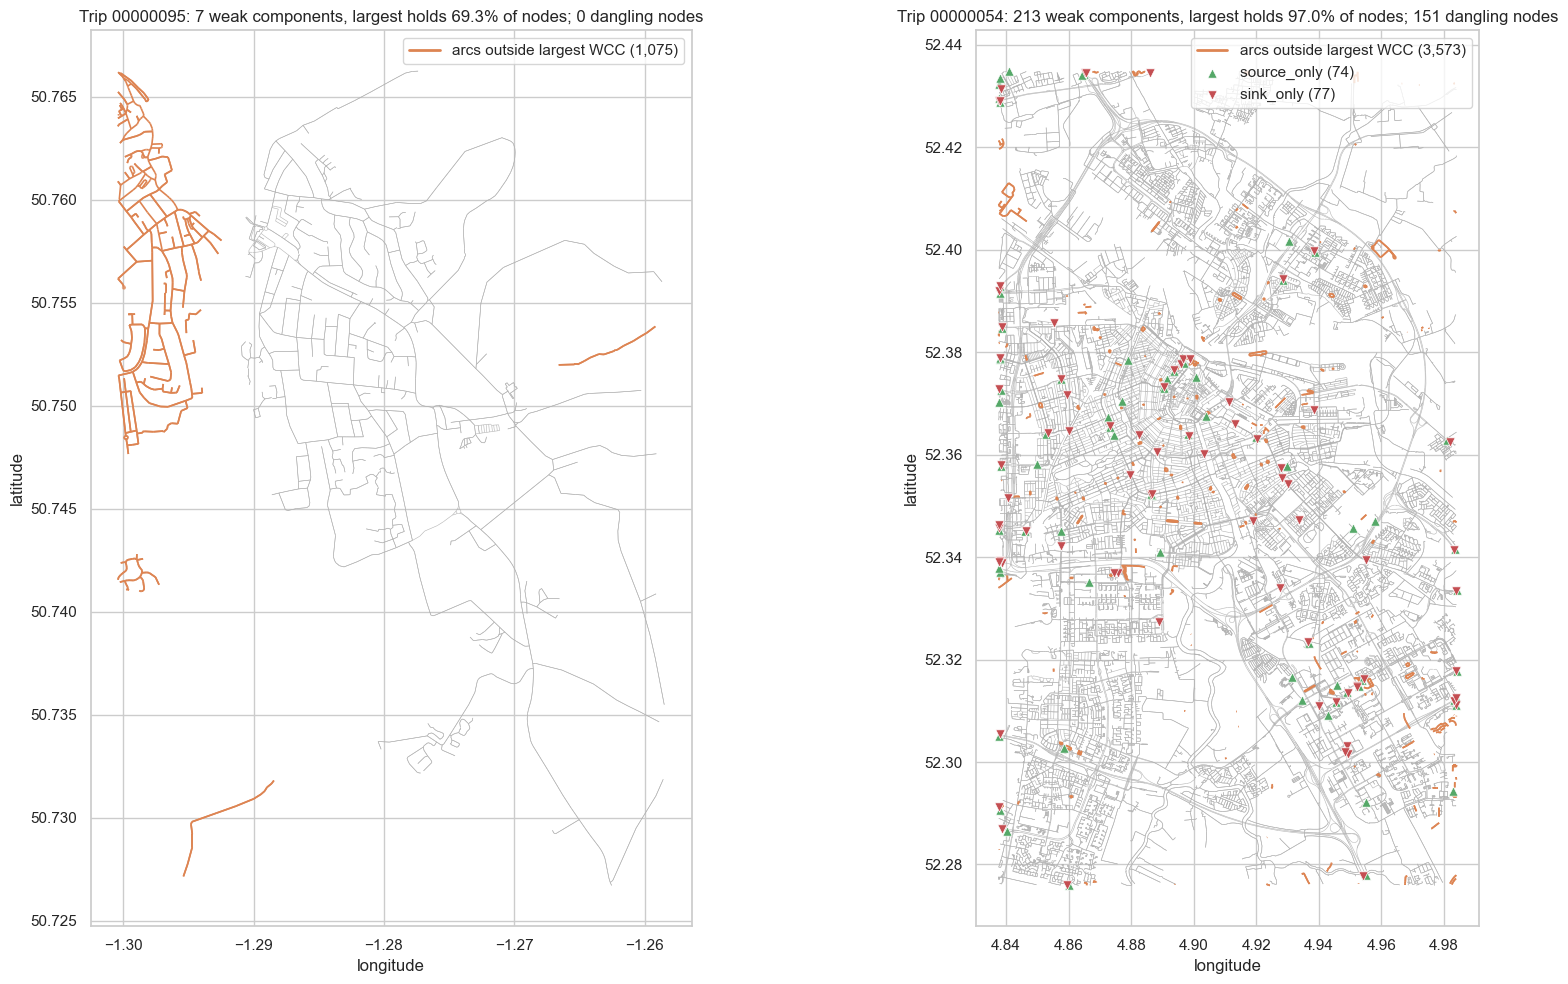

In [20]:
del G_rep, geo_rep  # free the representative graph before loading another one
c_tmp = connectivity.assign(dangling=connectivity.source_only_nodes + connectivity.sink_only_nodes + connectivity.isolated_nodes)
FRAG = c_tmp.nsmallest(1, "largest_wcc_pct").trip_id.iloc[0]
DANG = c_tmp.nlargest(1, "dangling").trip_id.iloc[0]

fig, axes = plt.subplots(1, 2, figsize=(18, 10))
for ax, tid in zip(axes, [FRAG, DANG]):
    nodes_x, arcs_x, _ = rn.load_road_network(tid, trips_index, scan=False)
    G_x, _, _ = rn.build_road_graph(nodes_x, arcs_x)
    _, sizes_x = rn.calculate_connectivity_statistics(G_x, return_sizes=True)
    geo_x = rn.get_road_segment_geometry(nodes_x, arcs_x)
    lw = np.isin(geo_x.from_node_id, list(sizes_x["largest_wcc"]))
    plot_segments(ax, geo_x[lw], colors="0.7", linewidths=0.4)
    plot_segments(ax, geo_x[~lw], colors="#DD8452", linewidths=1.2)
    ax.plot([], [], color="#DD8452", lw=2, label=f"arcs outside largest WCC ({int((~lw).sum()):,})")
    dn = dangling_nodes[dangling_nodes.trip_id == tid]
    for cat, color, marker in [("isolated", "black", "x"), ("source_only", "#55A868", "^"), ("sink_only", "#C44E52", "v")]:
        d = dn[dn.category == cat]
        if len(d):
            ax.scatter(d.longitude, d.latitude, c=color, marker=marker, s=45, zorder=4, edgecolors="white", linewidths=0.5,
                       label=f"{cat} ({len(d)})")
    row = c_tmp.set_index("trip_id").loc[tid]
    ax.set_title(f"Trip {tid}: {int(row.n_weak_components)} weak components, largest holds "
                 f"{row.largest_wcc_pct:.1f}% of nodes; {int(row.dangling)} dangling nodes")
    ax.legend(loc="upper right")
    del G_x, geo_x
plt.tight_layout(); plt.savefig(FIG_DIR / "network_fragments_and_dangling.png", dpi=120, bbox_inches="tight"); plt.show()

## 8. Graph-builder verification on real trips
`build_road_graph()` is checked on one **train** trip and one **student-test** trip:

* graph node count = rows in `.nodes`; graph edge count = valid arcs;
* every edge key equals its original `arc_id` and its endpoints equal the original `.arcs` row (all arcs checked);
* node attributes equal the `.nodes` coordinates;
* invalid references, connectivity statistics and isolated-node detection agree with the batch results.

In [21]:
verification = []
for part, tid in EXAMPLES.items():
    nodes_df, arcs_df = example_tables[tid]
    G, val, summ = rn.build_road_graph(nodes_df, arcs_df)
    assert G.number_of_nodes() == len(nodes_df)
    assert G.number_of_edges() == int(val.is_valid.sum()) == len(arcs_df) - summ["invalid_arcs"]
    edges = pd.DataFrame([(k, u, v, d["arc_id"], d["from_node_id"], d["to_node_id"]) for u, v, k, d in G.edges(keys=True, data=True)],
                         columns=["key", "u", "v", "arc_id", "from_attr", "to_attr"]).sort_values("arc_id").reset_index(drop=True)
    ref = arcs_df[val.is_valid.to_numpy()].reset_index(drop=True)
    assert (edges.key == edges.arc_id).all() and (edges.arc_id.to_numpy() == ref.arc_id.to_numpy()).all()
    assert (edges.u.to_numpy() == ref.from_node_id.to_numpy()).all() and (edges.v.to_numpy() == ref.to_node_id.to_numpy()).all()
    assert (edges.from_attr == edges.u).all() and (edges.to_attr == edges.v).all()
    sample = nodes_df.sample(n=100, random_state=SEED)
    assert all(G.nodes[r.node_id]["longitude"] == r.lon and G.nodes[r.node_id]["latitude"] == r.lat for r in sample.itertuples())
    conn = rn.calculate_connectivity_statistics(G)
    iso = rn.find_isolated_nodes(G)
    batch = connectivity.set_index("trip_id").loc[tid]
    assert conn["n_weak_components"] == batch.n_weak_components and conn["n_strong_components"] == batch.n_strong_components
    assert (iso.category == "isolated").sum() == batch.isolated_nodes
    verification.append({"trip_id": tid, "partition": part, "nodes_in_file": len(nodes_df), "graph_nodes": G.number_of_nodes(),
                         "arcs_in_file": len(arcs_df), "graph_edges": G.number_of_edges(), "arc_ids_preserved": True,
                         "invalid_node_references": summ["invalid_node_references"], "weak_components": conn["n_weak_components"],
                         "strong_components": conn["n_strong_components"], "largest_wcc_pct": round(conn["largest_wcc_pct"], 2),
                         "isolated": int((iso.category == "isolated").sum()), "source_only": int((iso.category == "source_only").sum()),
                         "sink_only": int((iso.category == "sink_only").sum())})
    del G
display(pd.DataFrame(verification))
print("All graph-builder checks passed.")

,trip_id,partition,nodes_in_file,graph_nodes,arcs_in_file,graph_edges,arc_ids_preserved,invalid_node_references,weak_components,strong_components,largest_wcc_pct,isolated,source_only,sink_only
0,00000001,train,88809,88809,165790,165790,True,0,175,1942,97.8,0,69,81
1,00000000,student-test,8542,8542,18196,18196,True,0,100,102,87.4,0,1,0


All graph-builder checks passed.


### 8.1 Usage for other members
```python
from pathsnap.data.loader import discover_trips
from pathsnap import road_network as rn

idx = discover_trips()                                  # Member 1 loader
nodes_df, arcs_df, report = rn.load_road_network("00000001", idx)
G, arc_validation, summary = rn.build_road_graph(nodes_df, arcs_df)

u, v, attrs = rn.get_edge_by_arc_id(G, 1234)            # arc_id -> (from, to, {arc_id, from_node_id, to_node_id, length_m})
G.nodes[u]["longitude"], G.nodes[u]["latitude"]
geom = rn.get_road_segment_geometry(nodes_df, arcs_df, arc_ids=[1234, 1235])  # endpoints, length_m, bearing_deg
stats = rn.calculate_connectivity_statistics(G)
```

## 9. Export outputs

In [22]:
summary.to_csv(EDA_DIR / "road_network_summary.csv", index=False)
connectivity.to_csv(EDA_DIR / "connectivity_summary.csv", index=False)
for f in sorted(EDA_DIR.rglob("*")):
    if f.is_file():
        print(f"{f.relative_to(REPO_ROOT).as_posix():60s} {f.stat().st_size / 1024:8.1f} KB")

outputs/eda/component_size_distribution.csv                       7.4 KB
outputs/eda/connectivity_summary.csv                              8.7 KB
outputs/eda/degree_distribution.csv                               1.3 KB
outputs/eda/figures/component_sizes.png                          67.1 KB
outputs/eda/figures/degree_distributions.png                     37.3 KB
outputs/eda/figures/mean_degree_per_trip.png                     26.6 KB
outputs/eda/figures/network_connections_00000022.png            127.4 KB
outputs/eda/figures/network_fragments_and_dangling.png          856.9 KB
outputs/eda/figures/network_full_00000022.png                   320.2 KB
outputs/eda/figures/network_size_overview.png                    82.2 KB
outputs/eda/figures/network_zoom_00000022.png                   171.1 KB
outputs/eda/invalid_arcs_report.csv                             182.8 KB
outputs/eda/isolated_nodes_report.csv                            97.3 KB
outputs/eda/road_network_file_heads.csv            

## 10. Findings

In [23]:
s, c = summary, connectivity
facts = [
    f"{len(s)} trips analysed ({(s.partition=='train').sum()} train, {(s.partition=='student-test').sum()} student-test); "
    f"{s.n_nodes.sum():,} nodes and {s.n_arcs.sum():,} arcs in total.",
    f"Network size varies widely: {s.n_nodes.min():,} – {s.n_nodes.max():,} nodes (median {int(s.n_nodes.median()):,}), "
    f"{s.n_arcs.min():,} – {s.n_arcs.max():,} arcs (median {int(s.n_arcs.median()):,}).",
    f"File integrity: {int(s.malformed_node_rows.sum() + s.malformed_arc_rows.sum())} malformed rows, "
    f"{int(s.missing_coordinates.sum())} missing coordinates, {int(s.invalid_coordinates.sum())} invalid coordinates, "
    f"{int(s.invalid_node_references.sum())} invalid node references.",
    f"{int(s.duplicate_arcs.sum())} duplicate directed arcs in {(s.duplicate_arcs>0).sum()} trips, "
    f"{int(s.self_loops.sum())} self-loops in {(s.self_loops>0).sum()} trips, "
    f"{int(s.duplicate_nodes.sum())} duplicate-coordinate nodes in {(s.duplicate_nodes>0).sum()} trips, "
    f"{int(s.zero_length_arcs.sum())} zero-length arcs. All are kept and flagged.",
    f"Median share of arcs that have a reverse arc: {s.two_way_arc_share.median():.1%} "
    f"(min {s.two_way_arc_share.min():.1%}); arcs ≈ {(s.n_arcs/s.n_nodes).median():.2f} × nodes.",
    f"Median arc length per trip ranges {s.median_arc_length_m.min():.1f} – {s.median_arc_length_m.max():.1f} m.",
    f"Weakly connected trips: {int(c.is_weakly_connected.sum())}/{len(c)}; strongly connected: {int(c.is_strongly_connected.sum())}/{len(c)}.",
    f"Largest WCC holds a median {c.largest_wcc_pct.median():.2f}% of nodes (min {c.largest_wcc_pct.min():.2f}%, trip "
    f"{c.loc[c.largest_wcc_pct.idxmin(), 'trip_id']}); largest SCC a median {c.largest_scc_pct.median():.2f}% (min {c.largest_scc_pct.min():.2f}%).",
    f"Isolated nodes: {int(c.isolated_nodes.sum())}. Dangling source-only: {int(c.source_only_nodes.sum())}, sink-only: {int(c.sink_only_nodes.sum())}.",
    f"Mean total degree per trip: median {c.mean_total_degree.median():.2f}; max node degree {int(c.max_total_degree.max())}.",
]
for i, f in enumerate(facts, 1):
    print(f"{i:2d}. {f}")

 1. 90 trips analysed (80 train, 10 student-test); 2,024,174 nodes and 4,061,945 arcs in total.
 2. Network size varies widely: 299 – 155,003 nodes (median 9,305), 649 – 307,392 arcs (median 18,761).
 3. File integrity: 0 malformed rows, 0 missing coordinates, 0 invalid coordinates, 0 invalid node references.
 4. 1903 duplicate directed arcs in 60 trips, 24 self-loops in 9 trips, 92 duplicate-coordinate nodes in 37 trips, 106 zero-length arcs. All are kept and flagged.
 5. Median share of arcs that have a reverse arc: 95.1% (min 35.1%); arcs ≈ 2.03 × nodes.
 6. Median arc length per trip ranges 6.7 – 84.9 m.
 7. Weakly connected trips: 1/90; strongly connected: 0/90.
 8. Largest WCC holds a median 98.02% of nodes (min 69.28%, trip 00000095); largest SCC a median 96.42% (min 63.59%).
 9. Isolated nodes: 0. Dangling source-only: 952, sink-only: 955.
10. Mean total degree per trip: median 4.07; max node degree 16.


### Interpretation and implications for route validation / HMM

* **Files are structurally clean.** Every row of every `.nodes` / `.arcs` file parses with exactly two fields, and every
  arc endpoint is a valid node index, so all arcs can be placed in the graph and `arc_id` = row index is safe to rely on.
* **Duplicates and self-loops are rare but real.** They are kept as separate keyed edges in the `MultiDiGraph`, because a
  `.route` may legitimately reference any `arc_id`. Shortest-path code should be aware that parallel arcs between the same
  nodes exist (use the minimum `length_m` among them).
* **Mostly two-way streets.** In most trips the large majority of arcs have a reverse twin, which is why the arc count is
  close to 2 × node count. Six trips have a two-way share below 80 % (trip `00000080` only about 35 %), so direction must
  not be ignored when routing.
* **Networks are not fully connected.** Only one trip (`00000063`) is a single weak component and **no** trip is strongly
  connected. Each trip has a dominant weak component plus small fragments. Some fragments are roads cut off by the
  bounding box of the extracted area (e.g. the western block of trip `00000095`), but in dense cities such as trip
  `00000054` many small fragments and dangling nodes lie inside the network, so they are not only a border effect. Strong components are
  smaller than weak ones because of one-way arcs and dead ends (source-only / sink-only nodes). In the representative trip,
  a long major road belongs to the largest WCC but not to the largest SCC, i.e. it can be reached but not driven
  back from (or the reverse) inside the extracted area.
* **One singleton component without an isolated node.** Trip `00000035` has a node whose only arcs are two self-loops
  (arc IDs 31470 and 31471). It is formally connected to nothing else; a route can never pass through it to another node.
* **HMM consequences.** Candidate arcs in small fragments or outside the largest SCC can make Viterbi transitions
  impossible. Recommended handling for the map-matcher: precompute the SCC / WCC id of every node (with
  `calculate_connectivity_statistics(..., return_sizes=True)`), give an unreachable transition a small non-zero penalty
  rather than probability 0, and break the HMM chain when no candidate pair is reachable.
* **Degrees.** Road intersections have small degrees (total degree is mostly 2–8 in the directed graph), consistent with
  ordinary street networks; there are no degree outliers that would suggest corrupted data.